Project Description- For this project our goal is to build two SVM models and a decision tree model using one data set. The dataset we chose was the  Banknote Authentication dataset from UCI it has 1,372 samples and 4 measurements taken from banknote images. So our specific goal in this project is to use this dataset to predict whether a banknote is genuine or counterfeit. We will use the same training and testing data for all three models to make it a fair test and then compare their accuracy and give our conclusion. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score

from ucimlrepo import fetch_ucirepo

# Fetch the dataset from UCI
banknote_authentication = fetch_ucirepo(id=267)

# Data (as pandas dataframes)
X = banknote_authentication.data.features
y = banknote_authentication.data.targets

df = X.copy()
df["Class"] = y["class"]

df.head()

,variance,skewness,curtosis,entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


We use df.shape to give us the number of rows and columns in the dataset and there are 1,372 samples with 4 measurement columns and 1 class column 

In [2]:
df.shape

(1372, 5)

And then df.info was used just to see all the columns and their data types and if any are missing, which none appear to be missing

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


df.describe is used to look at the useful stats form the measurements including their means, standard deviation and min/max

In [4]:
df.describe()

,variance,skewness,curtosis,entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


This is to count how many samples are in each of the two classes

In [5]:
df["Class"].value_counts()

Class
0    762
1    610
Name: count, dtype: int64

Now we made a bar graph to see how many samples belong to each class in this dataset

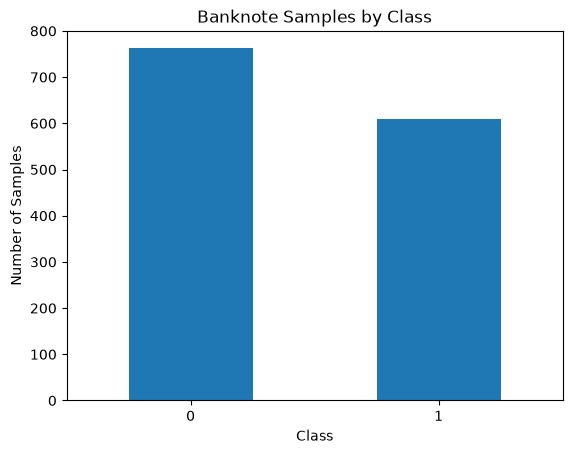

In [6]:
df["Class"].value_counts().plot(kind="bar")
plt.title("Banknote Samples by Class")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

And these are the histograms we made of the 4 measurements so we can see the variance, skewness, curtosis and entropy values spread out

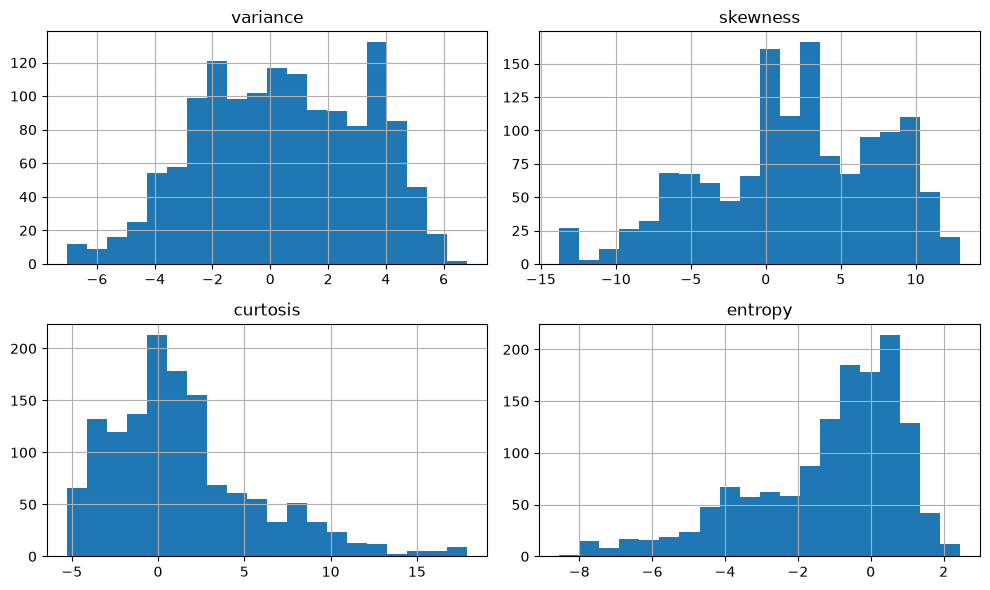

In [7]:
df[["variance", "skewness", "curtosis", "entropy"]].hist(bins=20, figsize=(10, 6))
plt.tight_layout()
plt.show()

Now we can separate the X values from the Y values. X contains the four banknote measurements and y contains the class that we want to predict

In [8]:
X = df.drop(columns=["Class"])
y = df["Class"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1372, 4)
y shape: (1372,)


We then split the data into training and testing sets and used the 80/20 to train and test them

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1097
Testing samples: 275


In this section we scaled the features using StandardScaler. The measurements have different ranges so we fit the scaler using the training set and then applied the same scaling to the test set

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("First four scaled values:", X_train_scaled[0])

First four scaled values: [-0.6391558   1.80557961 -0.18836535 -3.05096841]


Here we created the first SVM model without a nonlinear kernel using LinearSVC and then we trained the model using the scaled training data and then used predict() to make the predictions on the scaled test set. We also had to use max_iter=10000 because we got a convergence warning and needed to increase our amount of iterations

In [11]:
linear_svm = LinearSVC(C=1, loss="hinge", random_state=42,max_iter=10000)
linear_svm.fit(X_train_scaled, y_train)

y_pred_linear = linear_svm.predict(X_test_scaled)

print("First 10 predictions:", y_pred_linear[:10])
print("First 10 actual values:", y_test.values[:10])

First 10 predictions: [0 0 0 0 0 0 0 0 0 0]
First 10 actual values: [0 0 0 0 0 0 0 0 0 0]


In this section we can now calculate the accuracy of the linear SVM model

In [12]:
linear_accuracy = accuracy_score(y_test, y_pred_linear)
print("Linear SVM Accuracy:", linear_accuracy)

Linear SVM Accuracy: 0.9818181818181818


Now we need to create our second SVM model using the RBF kernel and this kernel is meant to allow the SVM to separate the data using a nonlinear decision boundary.

In [13]:
rbf_svm = SVC(kernel="rbf", gamma="scale", C=1)
rbf_svm.fit(X_train_scaled, y_train)

y_pred_rbf = rbf_svm.predict(X_test_scaled)

print("First 10 predictions:", y_pred_rbf[:10])
print("First 10 actual values:", y_test.values[:10])

First 10 predictions: [0 0 0 0 0 0 0 0 0 0]
First 10 actual values: [0 0 0 0 0 0 0 0 0 0]


And again we calculate the accuracy of the second SVM model with the RBF kernel

In [14]:
rbf_accuracy = accuracy_score(y_test, y_pred_rbf)
print("RBF SVM Accuracy:", rbf_accuracy)

RBF SVM Accuracy: 1.0


In this section we are going to train the Decision model using the original training data since DT's do not require feature scaling

In [15]:
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

After training the Decision Tree model, we use the testing data to make some predictions. We then compared the first 10 predicted values with the first 10 actual values

In [16]:
y_pred_tree = tree_clf.predict(X_test)

print("First 10 Predictions", y_pred_tree[:10])
print("First 10 actual values", y_test.values[:10])

First 10 Predictions [0 0 0 0 0 0 0 0 0 0]
First 10 actual values [0 0 0 0 0 0 0 0 0 0]


We then calculate the accuracy of the Decision Tree model

In [17]:
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy", tree_accuracy)

Decision Tree Accuracy 0.9818181818181818


We then visualize the Decision Tree to understand how the model makes its decisions. This goes through the decisions the model makes to classify whether a banknote is genuine or not. 

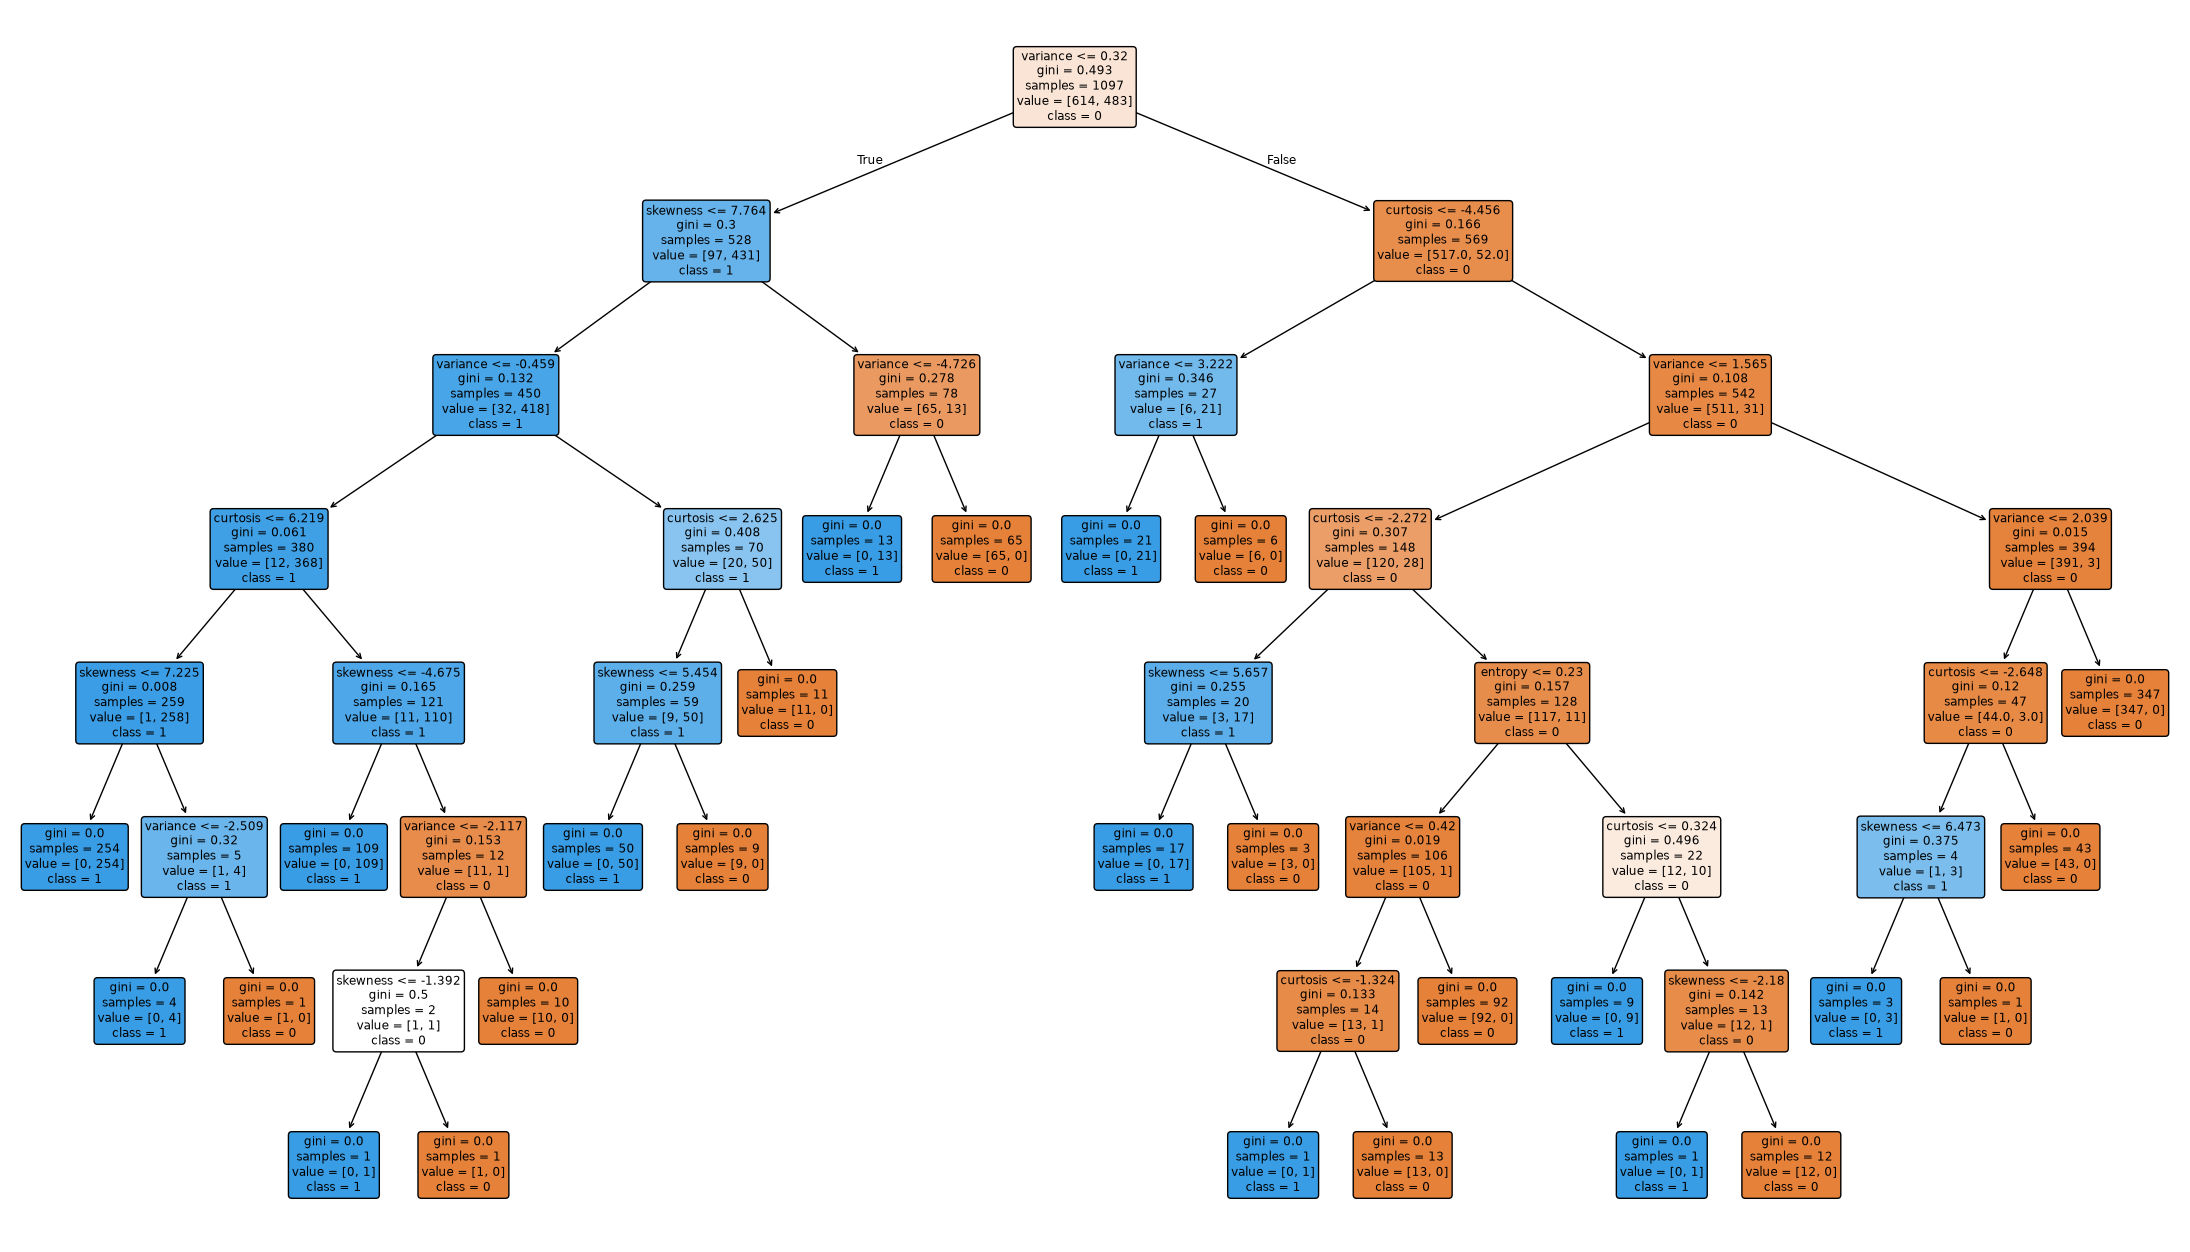

In [18]:
from sklearn.tree import plot_tree

plt.figure(figsize=(28, 16))

plot_tree(tree_clf,
         feature_names=X.columns,
         class_names=["0", "1"],
         rounded=True,
         filled=True)

plt.show()

This cell is to display the comparison between all three of the models we tested

In [19]:
print("Linear SVM Accuracy", linear_accuracy)
print("RBF SVM Accuracy", rbf_accuracy)
print("Decision Tree Accuracy", tree_accuracy)

Linear SVM Accuracy 0.9818181818181818
RBF SVM Accuracy 1.0
Decision Tree Accuracy 0.9818181818181818


After training and testing the three models for the Banknote Authentication dataset, we found that the SVM with the RBF Kernel performed the best which held a 100% accuracy. Both the Linear SVM and Decision Tree models achieved an accuracy of 98%. Overall, all three of the models were effective at classifying the banknotes, but the SVM with the RBF Kernel outperformed the other two on our testing data. 